In [30]:
import pandas as pd
import numpy as np
from pathlib import Path
import math
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from matplotlib.ticker import FuncFormatter
import warnings
from statsmodels.nonparametric.kernel_regression import KernelReg
from statsmodels.nonparametric.smoothers_lowess import lowess



In [31]:
!python smaparsing_indexes.py


sp500 1950-01-03 2026-10-20 19322  - duplicates: 0  - NaN cells: 0  - longest gap (in days): 7.0
/home/pedrosalgado22/Documents/Github Repositories/SMAstrategy/smaparsing_indexes.py:38: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"sma_{length}"] = df["Close"].rolling(window=length).mean() # calculates mean of rolling window of length and adds it as a new column to the dataframe
/home/pedrosalgado22/Documents/Github Repositories/SMAstrategy/smaparsing_indexes.py:38: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"sma_{le

In [32]:
original_data_path = Path.home() / "Documents" / "Github Repositories" / "SMAstrategy" / "data" / "raw"

processed_data_path = Path.home() / "Documents" / "Github Repositories" / "SMAstrategy" / "data" / "processed"

In [33]:
results_data_path = Path.home() / "Documents" / "Github Repositories" / "SMAstrategy" / "data" / "results"
results_data_path.mkdir(parents=True, exist_ok=True)

In [34]:
# sorry for excessive quotations, trying to quit lazy Ai code writing habits

In [35]:
# Indexes are only comparable between themselves, and not between each other for most cases - different starts, circumstances

In [36]:
PAYMENT = 500 # per month ( unrealistic, obviously. figurative value not accounting for inflation)
INTEREST_RATE = 0.03 # 3% interest rate for cash in the bank
START_DATE = "1986-01-01"

DIV_YIELD = {   # note: these are approximate values and may vary over time
    "sp500": 0.02, "nasdaq_comp": 0.01, "nasdaq100": 0.01, "ftse100": 0.04,
    "nikkei": 0.01, "dax": 0.0, "cac40": 0.03, "hang_seng": 0.03, "shanghai": 0.02,
    "euro_stoxx": 0.03, "nifty": 0.013, "dow_jones": 0.02,
}                                                                    


                    # dictionaries
STRATEGIES = {"DCA": None}          
for i in range(2, 201):
    STRATEGIES[f"SMA{i}"] = f"sma_{i}"

In [37]:
def simulate(df, sma_timeframe, dividend_yield, values=None): # function can receive a values argument, but it doesn't have to
    dates = df.index.tolist()
    closes = df["Close"].tolist()
    if sma_timeframe is not None:
        smas = df[sma_timeframe].tolist() # every days calculated sma in a list

    valid = df[(df.index >= START_DATE) & df["sma_200"].notna()]  # first day with sma_200 available. filtered dataframe with only "valid" rows
    start = df.index.get_loc(valid.index[0]) # first column where in valid. this will iterate for all datasets not one df with all indexes one per df
    end = df.index.get_loc(valid.index[-1])


    cash = 0
    units = 0
    units_bought = 0
    total_invested_stocks = 0
    last_sma_value_when_buying = 0
    total_invested = 0
    last_value_bought = 0
    n_buys = 0
    next_payment = dates[start].replace(day=1) + pd.DateOffset(months=1)       # next_payment = dates[start] + pd.Timedelta(days=(7 - dates[start].weekday()) % 7) for weekly simulations



    for i in range(start, end + 1):
        days = (dates[i] - dates[i - 1]).days # days between i row and i-1 row as int (.days returns int). used for interest/dividend calculations (since there are not rows for all days)
        cash = cash * (1 + INTEREST_RATE) ** (days / 365)
        units = units * (1 + dividend_yield) ** (days / 365)

        while next_payment <= dates[i]: # checks if payday has come
            cash += PAYMENT
            total_invested += PAYMENT # total invested is both cash and stock
            next_payment += pd.DateOffset(months=1) # next_payment += pd.Timedelta(days=7) for weekly simulations

        if sma_timeframe is None:
            signal = True       # if no sma_timeframe is provided, the signal is always True (DCA strategy)
        else:
            signal = closes[i - 1] < smas[i - 1] # if the previous day's close is below the previous day's sma_x, then the signal is True (buy signal)

        if cash > 0 and signal == True: # if there is cash available and the signal is True, then buy
            units = units + cash / closes[i-1]
            units_bought += cash / closes[i-1]
            total_invested_stocks += cash
            n_buys += 1
            cash = 0
            last_value_bought = closes[i-1]
            if sma_timeframe is not None:
                last_sma_value_when_buying = smas[i - 1]

        if values is not None:
            values.append(units * closes[i] + cash)   # so that we can plot the value of the portfolio over time later is not doing much here

    final_value = units * closes[-1] + cash
    keys = {
        "strategy_simulated": sma_timeframe if sma_timeframe is not None else "DCA",
        "start_date": dates[start].date(),
        "end_date": dates[-1].date(),
        "total_invested": total_invested,
        "total_invested_stocks": total_invested_stocks,
        "final_value": final_value,
        "total_return_pct": (final_value / total_invested - 1) * 100,
        "units": units,
        "avg_price": total_invested_stocks / units_bought if units_bought > 0 else None,
        "leftover_cash": cash,
        "n_buys": n_buys,
        "last_close": closes[i],
        "last_value_bought": last_value_bought,
        "last_sma_value_when_buying": last_sma_value_when_buying
    }

    return pd.DataFrame([keys], index=[keys["strategy_simulated"]]) # returns df with all those columns and index is the strategy

In [38]:
def run_index_simulator(df, name):
    results = [] # always need to maintain empty list to receive att
    for strategy, sma_timeframe in STRATEGIES.items():
        results.append(simulate(df, sma_timeframe, DIV_YIELD[name]))

        
    table = pd.concat(results)
    table.insert(0, "index", name)   # first column holds the index name
    return table

In [39]:
df = pd.read_csv(processed_data_path / "sp500_processed.csv", index_col=0, parse_dates=True)


In [40]:
run_index_simulator(df,"sp500")

,index,strategy_simulated,start_date,end_date,total_invested,total_invested_stocks,final_value,total_return_pct,units,avg_price,leftover_cash,n_buys,last_close,last_value_bought,last_sma_value_when_buying
DCA,sp500,DCA,1986-01-02,2026-10-20,244500,"244,500.00","4,113,672.82","1,582.48",535.59,833.92,0.00,489,"7,680.57","7,651.54",0.00
sma_2,sp500,sma_2,1986-01-02,2026-10-20,244500,"244,529.61","4,110,358.18","1,581.13",535.16,834.63,0.00,489,"7,680.57","7,651.54","7,661.19"
sma_3,sp500,sma_3,1986-01-02,2026-10-20,244500,"244,544.67","4,109,891.41","1,580.94",535.10,834.70,0.00,489,"7,680.57","7,651.54","7,668.69"
sma_4,sp500,sma_4,1986-01-02,2026-10-20,244500,"244,554.93","4,111,713.26","1,581.68",535.34,834.35,0.00,488,"7,680.57","7,651.54","7,687.37"
sma_5,sp500,sma_5,1986-01-02,2026-10-20,244500,"244,569.64","4,112,858.39","1,582.15",535.49,834.13,0.00,486,"7,680.57","7,651.54","7,690.72"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
sma_196,sp500,sma_196,1986-01-02,2026-10-20,244500,"244,333.83","4,050,893.60","1,556.81",527.03,841.98,"3,023.20",177,"7,680.57","6,528.52","6,652.03"
sma_197,sp500,sma_197,1986-01-02,2026-10-20,244500,"244,341.80","4,051,240.54","1,556.95",527.07,841.89,"3,023.20",176,"7,680.57","6,528.52","6,648.62"
sma_198,sp500,sma_198,1986-01-02,2026-10-20,244500,"244,437.14","4,052,480.23","1,557.46",527.23,841.86,"3,023.20",176,"7,680.57","6,528.52","6,645.26"
sma_199,sp500,sma_199,1986-01-02,2026-10-20,244500,"244,437.14","4,052,480.23","1,557.46",527.23,841.86,"3,023.20",176,"7,680.57","6,528.52","6,642.18"


In [41]:

pd.set_option("display.float_format", "{:,.2f}".format)   # no scientific notation, 2 decimals, thousands commas


all_tables = []
for name in DIV_YIELD:
    df = pd.read_csv(processed_data_path / f"{name}_processed.csv", index_col=0, parse_dates=True)
    all_tables.append(run_index_simulator(df, name))

all_tables = pd.concat(all_tables)


display(all_tables)
all_tables.to_parquet(results_data_path / "results_full200.parquet", index=False)

,index,strategy_simulated,start_date,end_date,total_invested,total_invested_stocks,final_value,total_return_pct,units,avg_price,leftover_cash,n_buys,last_close,last_value_bought,last_sma_value_when_buying
DCA,sp500,DCA,1986-01-02,2026-10-20,244500,"244,500.00","4,113,672.82","1,582.48",535.59,833.92,0.00,489,"7,680.57","7,651.54",0.00
sma_2,sp500,sma_2,1986-01-02,2026-10-20,244500,"244,529.61","4,110,358.18","1,581.13",535.16,834.63,0.00,489,"7,680.57","7,651.54","7,661.19"
sma_3,sp500,sma_3,1986-01-02,2026-10-20,244500,"244,544.67","4,109,891.41","1,580.94",535.10,834.70,0.00,489,"7,680.57","7,651.54","7,668.69"
sma_4,sp500,sma_4,1986-01-02,2026-10-20,244500,"244,554.93","4,111,713.26","1,581.68",535.34,834.35,0.00,488,"7,680.57","7,651.54","7,687.37"
sma_5,sp500,sma_5,1986-01-02,2026-10-20,244500,"244,569.64","4,112,858.39","1,582.15",535.49,834.13,0.00,486,"7,680.57","7,651.54","7,690.72"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
sma_196,dow_jones,sma_196,1992-10-14,2026-10-20,204000,"203,065.77","1,546,206.31",657.94,29.62,"10,891.81","3,023.20",162,"52,091.70","46,341.51","46,765.01"
sma_197,dow_jones,sma_197,1992-10-14,2026-10-20,204000,"203,072.08","1,546,332.15",658.01,29.63,"10,890.91","3,023.20",162,"52,091.70","46,341.51","46,741.69"
sma_198,dow_jones,sma_198,1992-10-14,2026-10-20,204000,"203,108.66","1,545,868.31",657.78,29.62,"10,895.04","3,023.20",162,"52,091.70","46,341.51","46,718.83"
sma_199,dow_jones,sma_199,1992-10-14,2026-10-20,204000,"203,108.42","1,545,746.48",657.72,29.62,"10,895.99","3,023.20",162,"52,091.70","46,341.51","46,697.71"


In [42]:
print(all_tables.columns)
display(all_tables.head())

Index(['index', 'strategy_simulated', 'start_date', 'end_date',
       'total_invested', 'total_invested_stocks', 'final_value',
       'total_return_pct', 'units', 'avg_price', 'leftover_cash', 'n_buys',
       'last_close', 'last_value_bought', 'last_sma_value_when_buying'],
      dtype='str')


,index,strategy_simulated,start_date,end_date,total_invested,total_invested_stocks,final_value,total_return_pct,units,avg_price,leftover_cash,n_buys,last_close,last_value_bought,last_sma_value_when_buying
DCA,sp500,DCA,1986-01-02,2026-10-20,244500,"244,500.00","4,113,672.82","1,582.48",535.59,833.92,0.00,489,"7,680.57","7,651.54",0.00
sma_2,sp500,sma_2,1986-01-02,2026-10-20,244500,"244,529.61","4,110,358.18","1,581.13",535.16,834.63,0.00,489,"7,680.57","7,651.54","7,661.19"
sma_3,sp500,sma_3,1986-01-02,2026-10-20,244500,"244,544.67","4,109,891.41","1,580.94",535.10,834.70,0.00,489,"7,680.57","7,651.54","7,668.69"
sma_4,sp500,sma_4,1986-01-02,2026-10-20,244500,"244,554.93","4,111,713.26","1,581.68",535.34,834.35,0.00,488,"7,680.57","7,651.54","7,687.37"
sma_5,sp500,sma_5,1986-01-02,2026-10-20,244500,"244,569.64","4,112,858.39","1,582.15",535.49,834.13,0.00,486,"7,680.57","7,651.54","7,690.72"


In [43]:

N_BINS = 10   # number of bars in the mean charts as a variable
TOP_N = 15    # how many SMAs in the top chart

colors = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple",
          "tab:brown", "tab:pink", "tab:gray", "tab:olive", "tab:cyan"]


finals = (
    all_tables.groupby("index")# groups by indexes, grabs only final value
    ["final_value"].apply(list)            # collects all final values and stores in a list
    .to_dict()                  # creates dictionaries
)


  # a dictionary with all indexes and final values inside for visualization purposes so sp 500 and 200 values respective of the 200 sma strats



In [44]:

names = list(DIV_YIELD)
strategy_names = list(STRATEGIES)   # # both of these create a list of the keys of these dictionaries above 


x_values = list(range(1, 201)) # would need to be updated if more smas are added
bin_size = round(len(strategy_names) / N_BINS) # round rounds if to nearest n if division was not perfect len is just 200 could just be = 200 / 10 only changes with addition of future smas n bins can change tho so not hard coded and rounded



bin_labels = [] 
for first in range(0, len(x_values), bin_size): # 0 to 200 jumping by 20 each iteration
    last = min(first + bin_size, len(x_values)) - 1  # last is first + bin size -1 so 19,39,59 and so on. len x values is (usually) 200 and to ensure it never goes over if values change ( first+ bin could surpass it)
    bin_labels.append(f"{x_values[first]}-{x_values[last]}") # 0-19, 20-39...

In [45]:


def get_bin_means(values):  # mean final amount of each bin


    means = []

    for first in range(0, len(values), bin_size): # 0, 20, 40, 60, 80, 100, 120, 140, 160, 180
        group = values[first:first + bin_size] # group = sma_index_listofvalues[1:20] creates a list with these values will create 10 lists in these intervals
        means.append(sum(group) / len(group))
    return means

In [46]:
n_rows = (len(names) + 2) // 3      # makes it 3 charts per row max in visualizations as i want to and is flexible with len names for future indexes added needs to be specified apriori



def make_grid():  # one square per index, hides the empty squares at the end
    fig, axes = plt.subplots(n_rows, 3, figsize=(18, 4 * n_rows))   # Creates a grid of plots with n_rows rows and 3 columns. Each row adds 4 inches to the figure height; the width is 18 inches.
    axes = axes.flatten()  # turns axes[0, 0]  # first plot and axes[0, 1]  # second plot into axes[0] or 1. makes axes[i] iteration easier after. figure is whole pic axes is each of the 12
    for j in range(len(names), len(axes)):
        axes[j].axis("off")   # iterates through unused axis so if i had for example 10 or 11 indexes since they go in 3s
    return axes

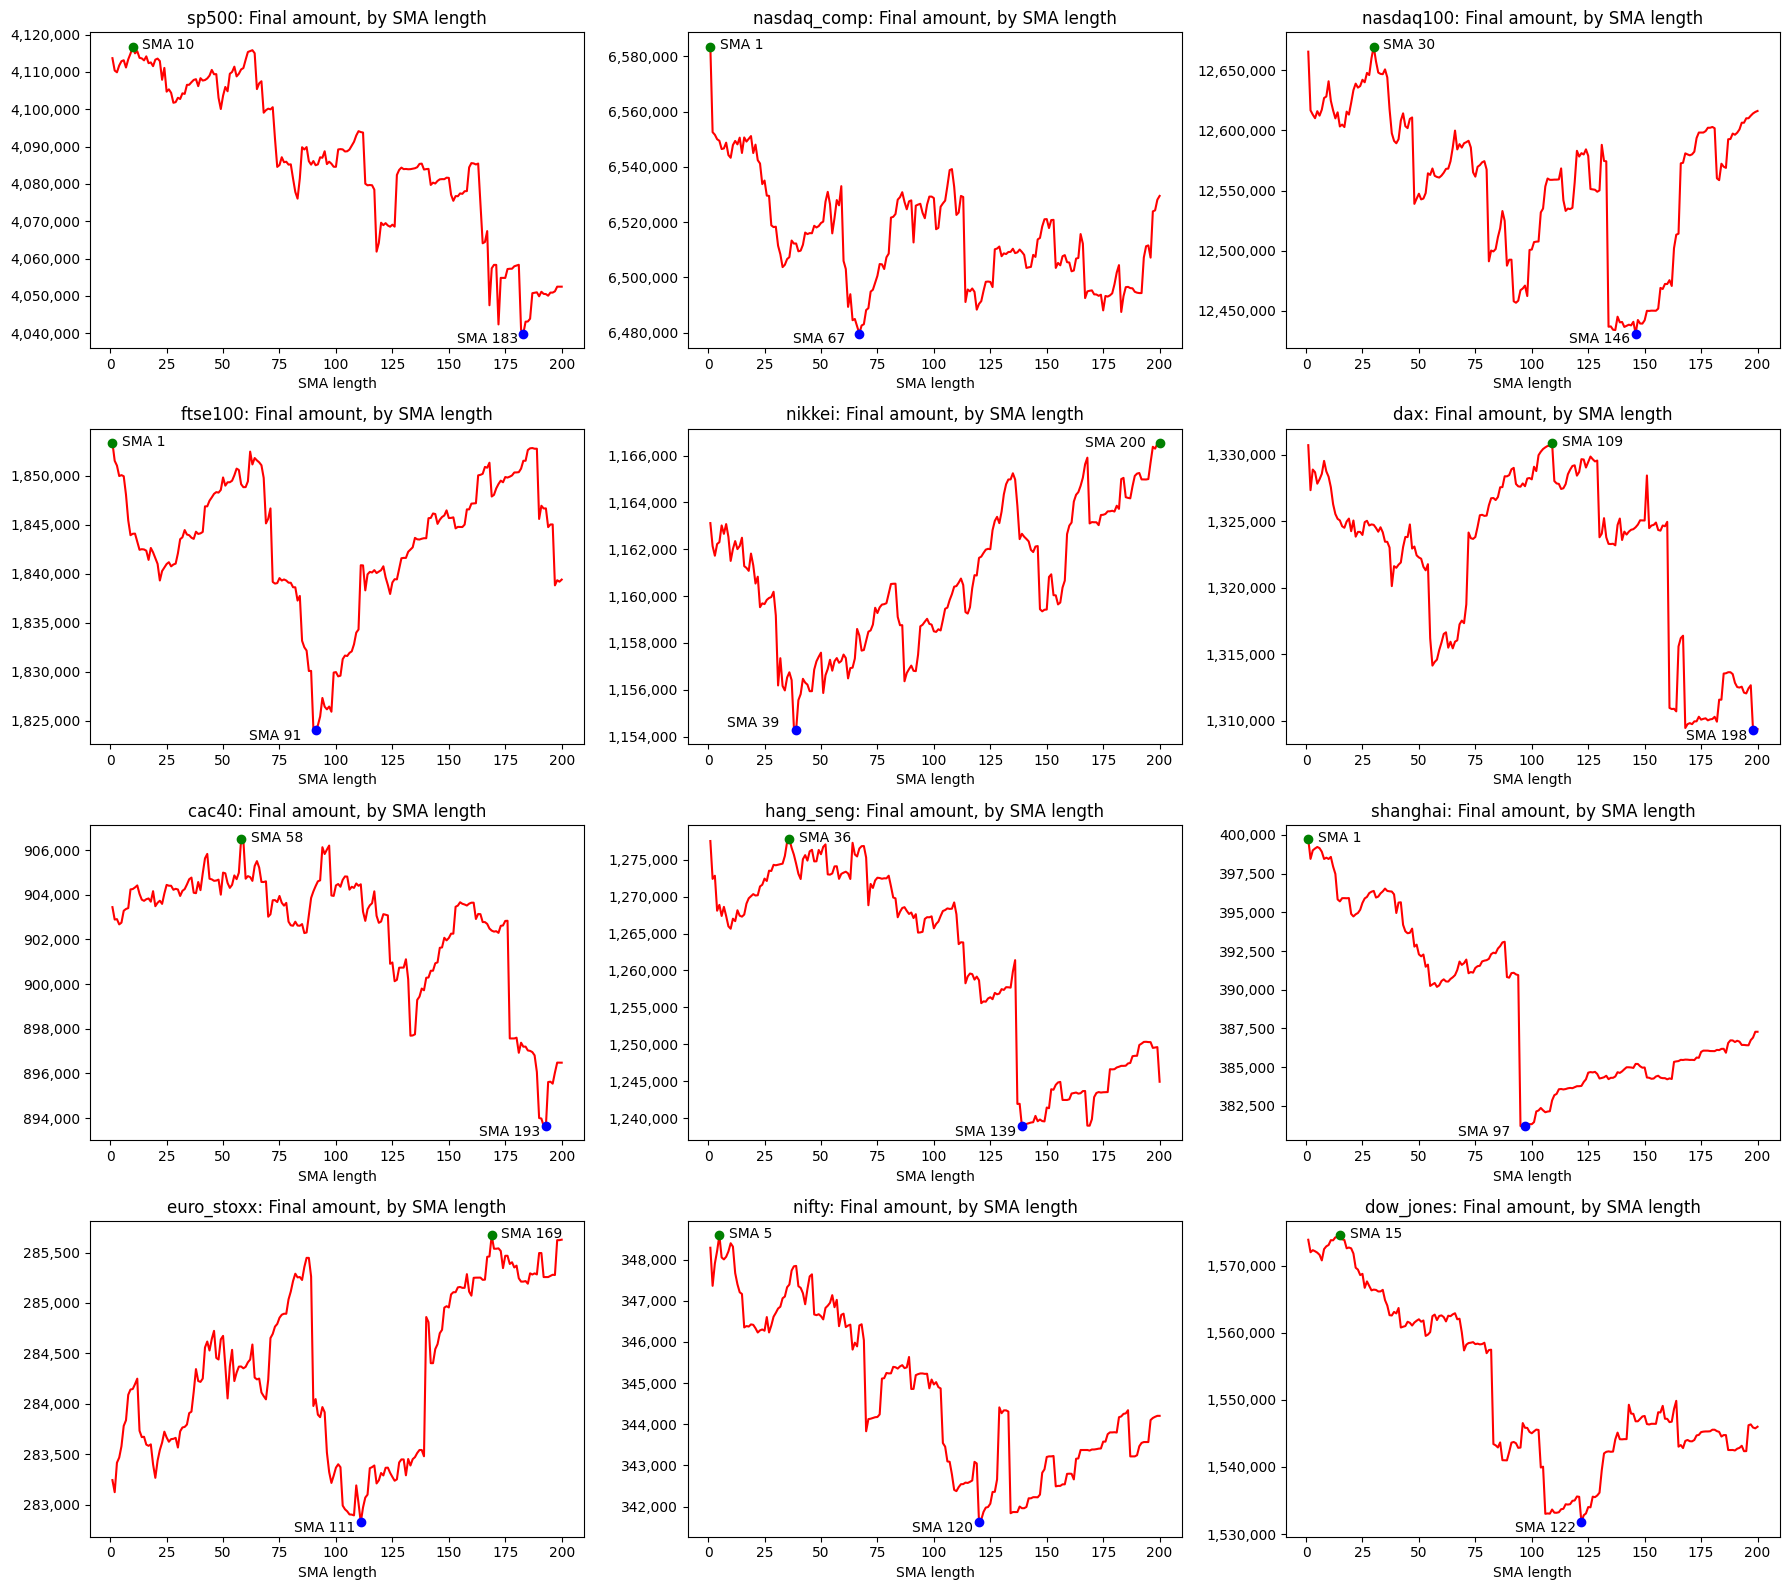

In [47]:
axes = make_grid()  # will create len(names) (12) axis no information carried yet with current settings set earlier fix column number variable n rows with number of index info transmitted as len names
for i in range(len(names)):
    ax = axes[i]  # iterates and selects each one axis and applies the settings below
    ax.plot(x_values, finals[names[i]], color="red") # sets y and x axis, x is just a list 1-200 , finals is a dict with keys=names and values from final value and i will iterate through all values for the specific index
    
    
    min_i = finals[names[i]].index(min(finals[names[i]]))  # finals[names[i]] is the iteration through all final values of an index so 200 values each iteration that is it list of 200 ints
    max_i = finals[names[i]].index(max(finals[names[i]]))  # max finds the max in the list list.index() finds its position but it only finds the first one so multiple numbers equal would need for loop
    ax.plot(x_values[min_i], finals[names[i]][min_i], "o", color="blue")
    ax.plot(x_values[max_i], finals[names[i]][max_i], "o", color="green")  # coords

    if names[i] == "nikkei":
        min_offset = (-50, 2)
        max_offset = (-54, -3)
    else:                                       # nikkei graph was a bit corrupted due to sma 200 max 
        min_offset = (-48, -7)
        max_offset = (7, -2)

    ax.annotate(   
        f"SMA {x_values[min_i]}",  # legend
        (x_values[min_i], finals[names[i]][min_i]), # coords
        xytext=min_offset,   # where to put the text relative to the point
        textcoords="offset points"        # tells Matplotlib how to interpret those numbers idk really understand these 2 lines               
    )

    ax.annotate(
        f"SMA {x_values[max_i]}",
        (x_values[max_i], finals[names[i]][max_i]),
        xytext=max_offset,
        textcoords="offset points"
    )


    ax.set_title(f"{names[i]}: Final amount, by SMA length")  # also i think ax.plot is what makes it a line chart the plot command is what carries that info
    ax.set_xlabel("SMA length")
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}")) # formats values in y axis to show as 4.100.ho000 and not 4e120000 or something like that
plt.tight_layout()  # auto adjuster for spacing does not hurt to have it
plt.show() # equivalent to print for plots

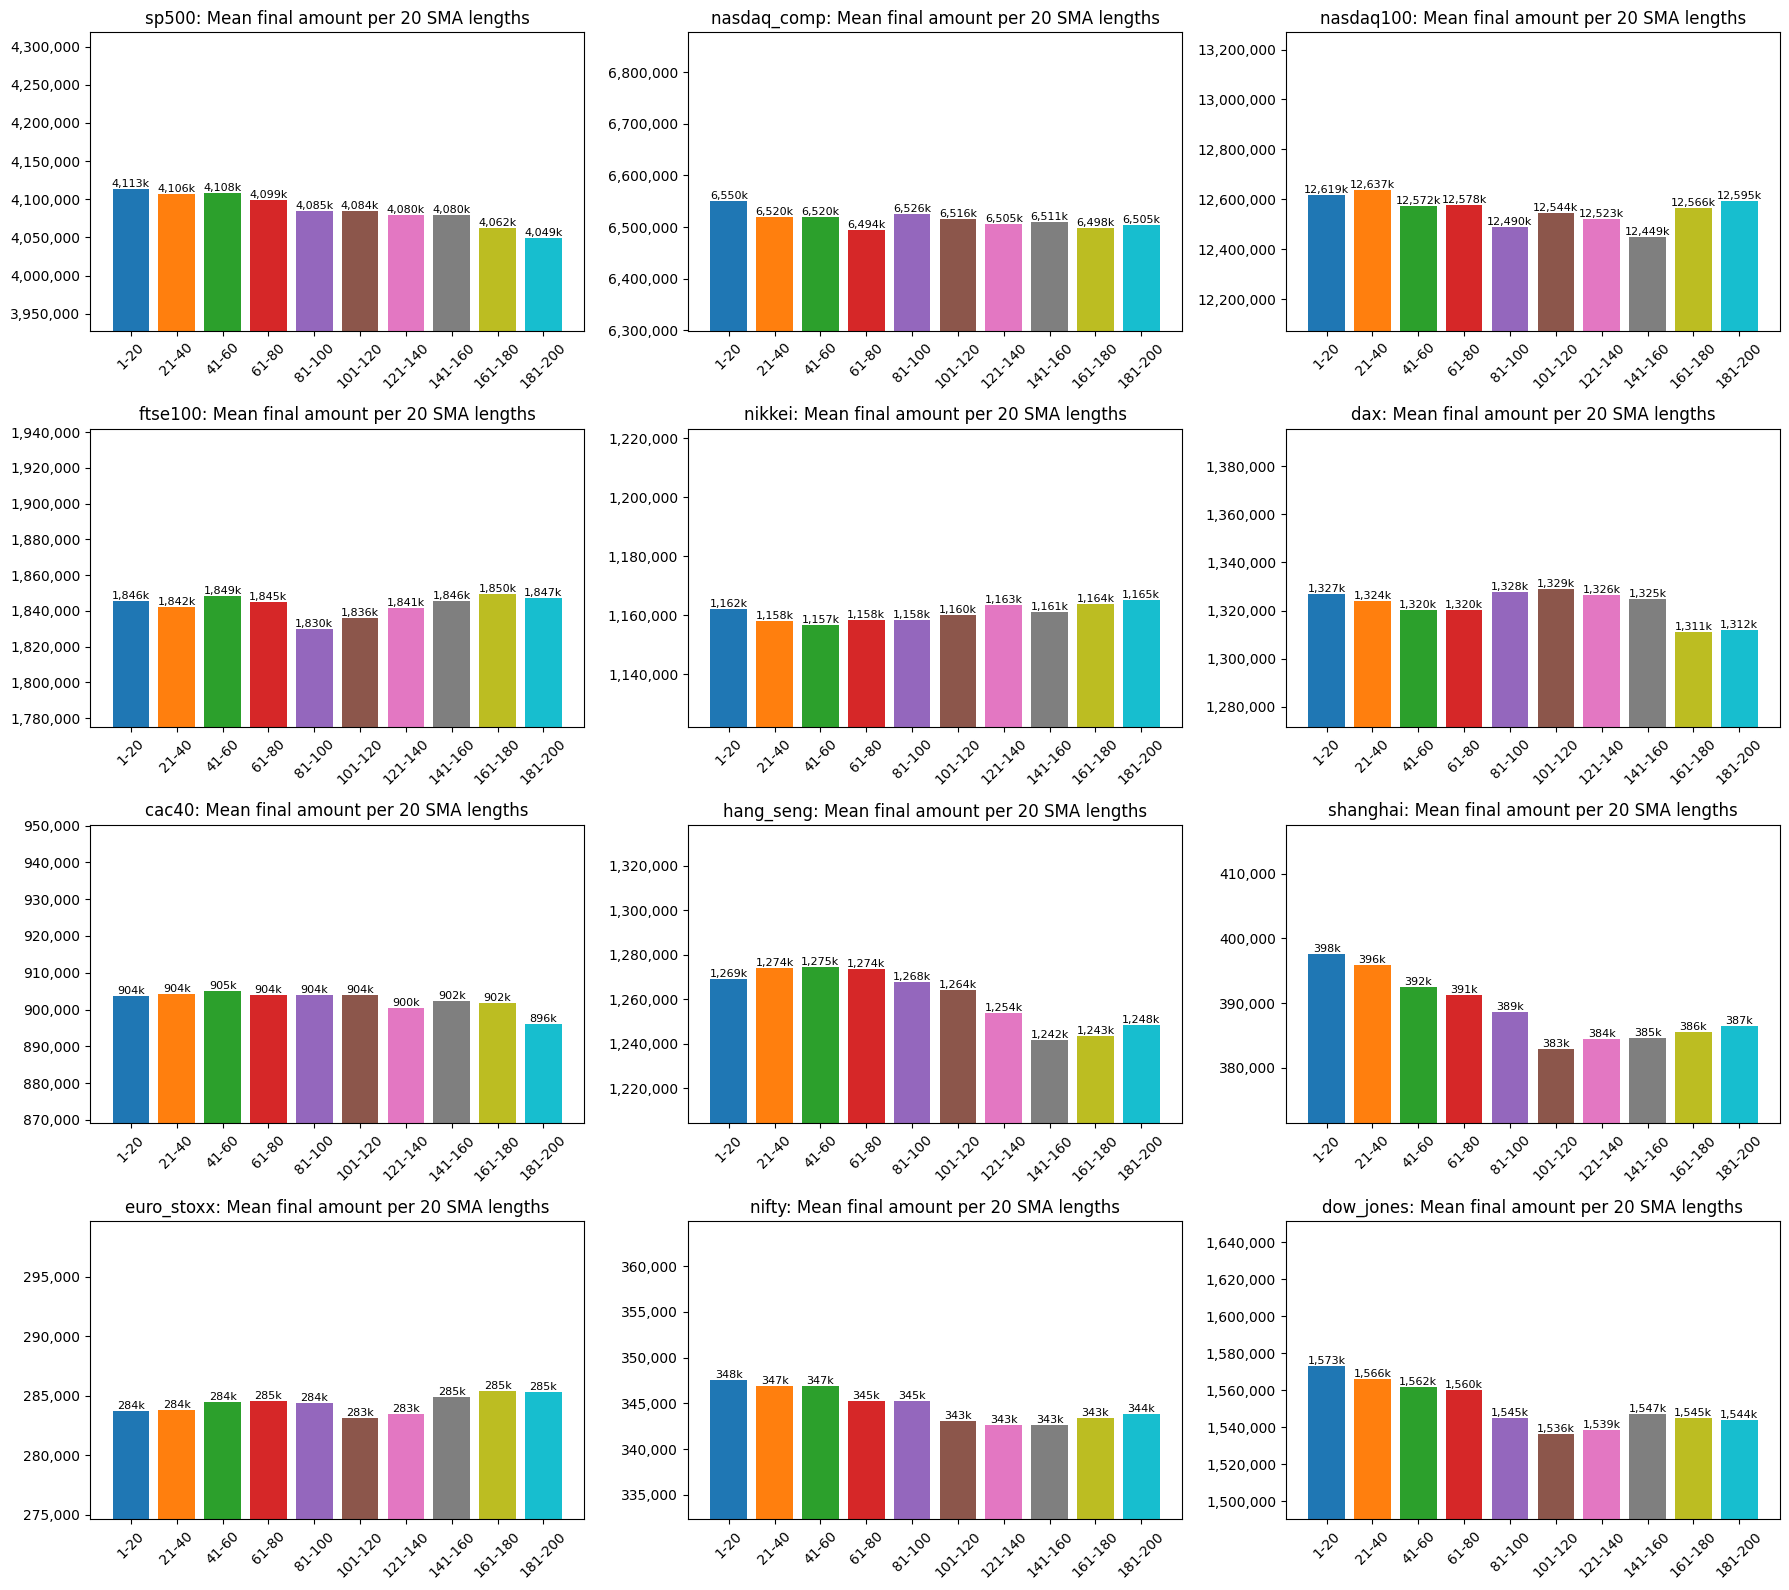

In [48]:
axes_2 = make_grid()
for i in range(len(names)):
    ax = axes_2[i]
    means = get_bin_means(finals[names[i]]) # uses the function earlier to get the means of smas by bins of the n_bins defined , means is a list
    labels = []
    for mean in means:
        labels.append(f"{mean / 1000:,.0f}k")  
    bars = ax.bar(bin_labels, means, color=colors)
    ax.bar_label(bars, labels=labels, fontsize=8)  # sets bar labels the k values above them
    ax.set_ylim(bottom=min(means) * 0.97) # starts y axis at 97% of the min of list instead of 0. no visualization insight if bars started at 0
    ax.set_title(f"{names[i]}: Mean final amount per {bin_size} SMA lengths")
    ax.tick_params(axis="x", labelrotation=45)
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))  # commas and no decimal places
plt.tight_layout()
plt.show()

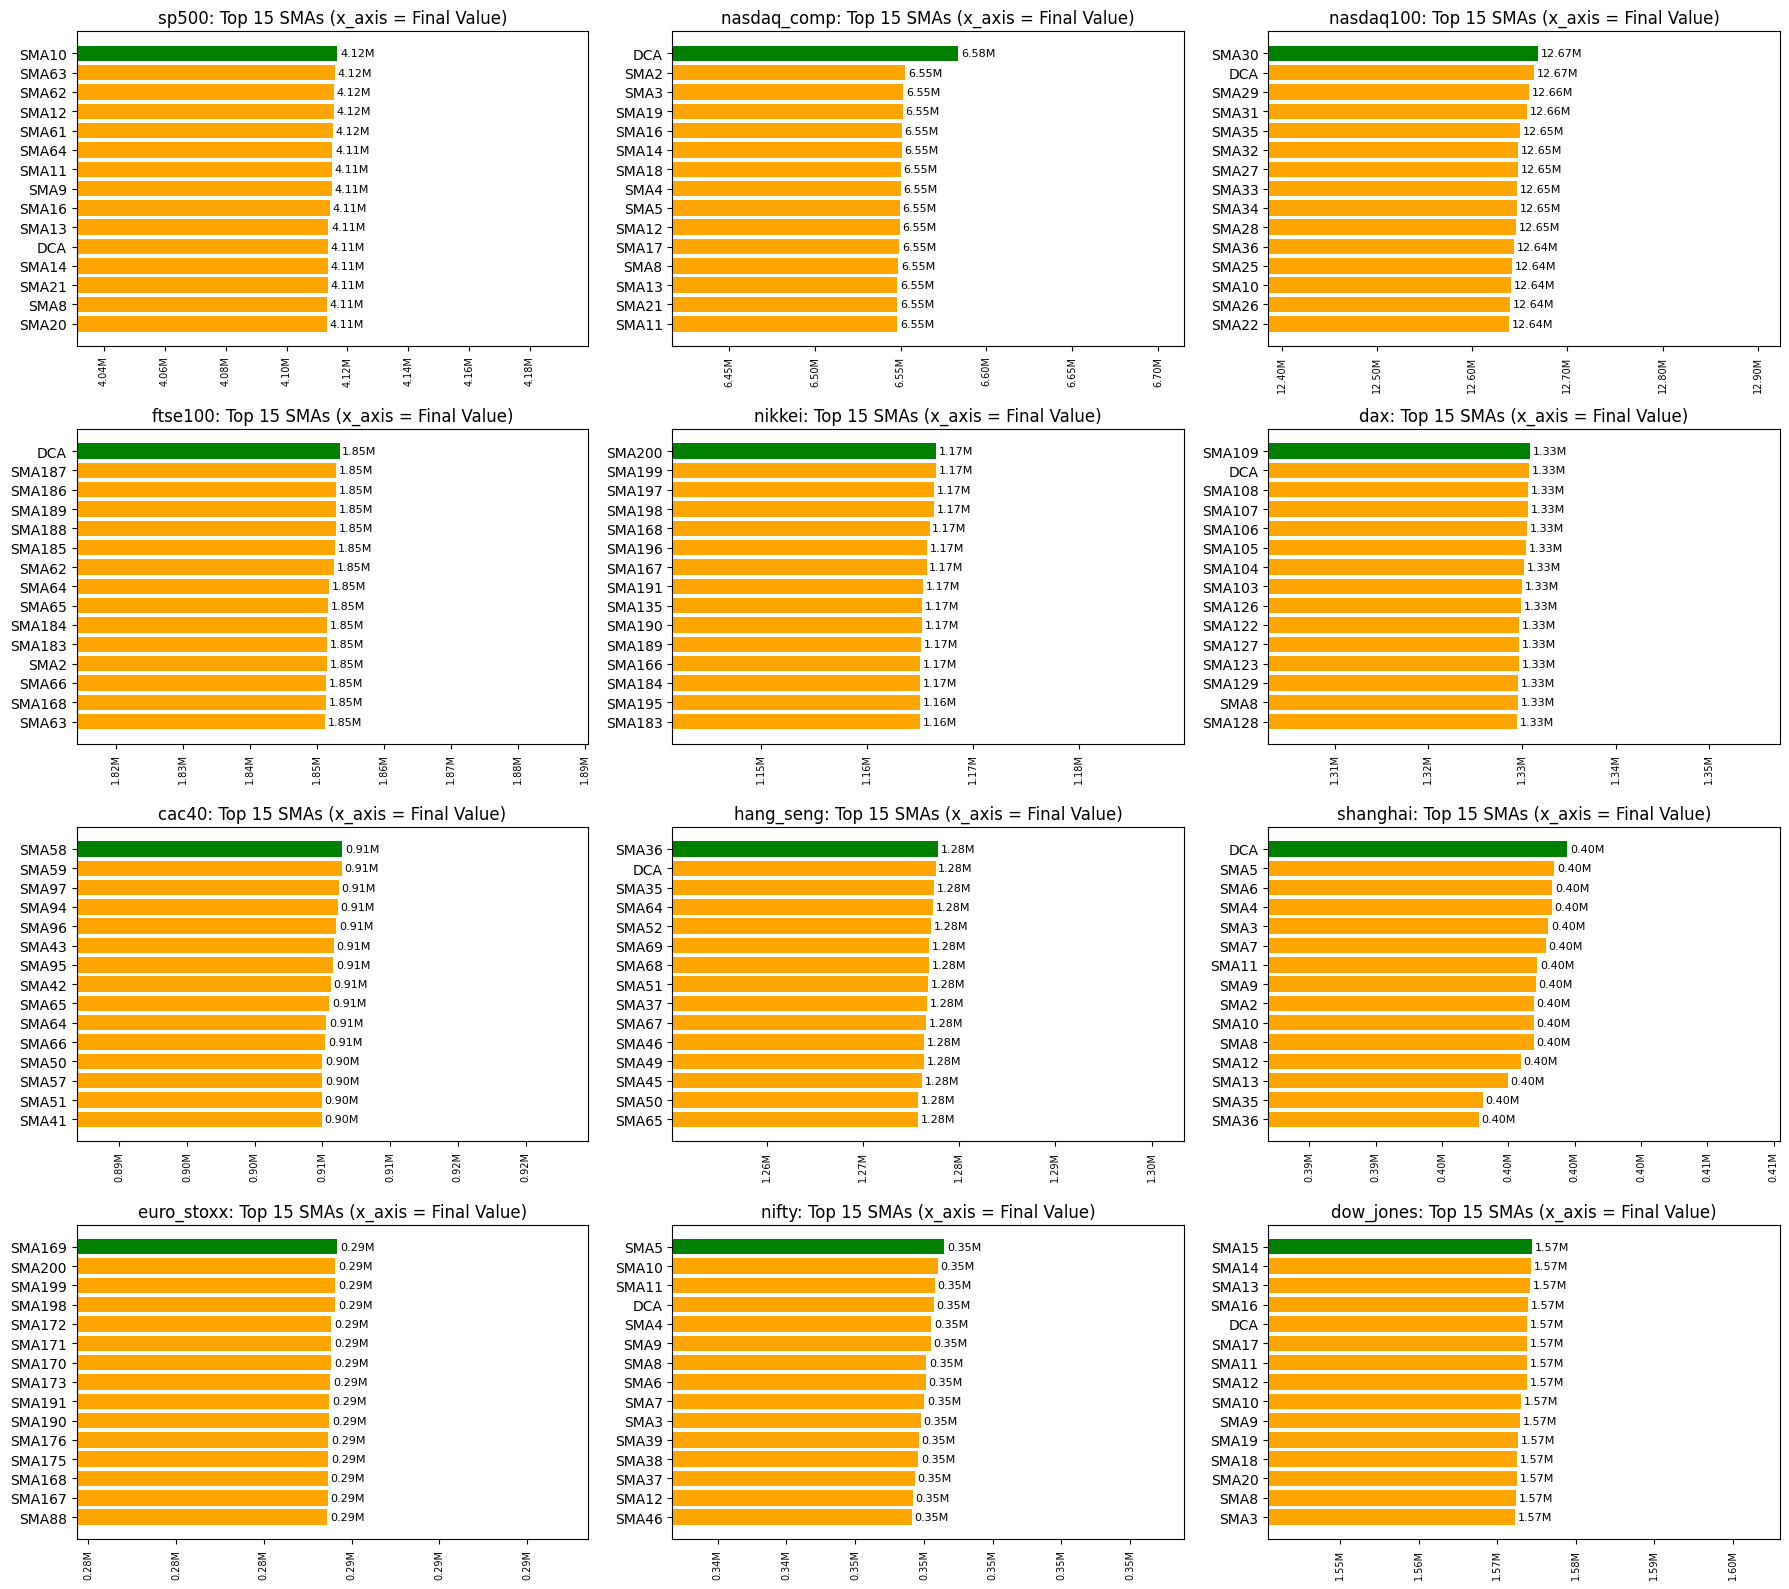

In [49]:
axes_3 = make_grid()
for i in range(len(names)):
    ax = axes_3[i]
    ranking = []
    for k in range(len(strategy_names)):
        ranking.append((finals[names[i]][k], strategy_names[k])) # creates a tuple with value of strategy name, strategy name [(12500, "SMA10"), (11000, "DCA")]
    ranking.sort(reverse=True)  # biggest final amount first

    top_names = [] # to store top n names
    top_values = []   # to store top n values
    labels = []     
    for rank in range(TOP_N):  # 15
        value, strategy = ranking[rank] # value, strategy will define both vars inside the ranking tuple, rank will be 15 as such will only be top 15 prev sorted by
        top_names.append(strategy)
        top_values.append(value)
        labels.append(f"{value / 1000000:.2f}M")



    colours = ["green"] + ["orange"] * (TOP_N - 1)  # how to highlight specific bars cool
    bars = ax.barh(top_names, top_values, color=colours)  # horizontal bar charts take y,x and not x,y inside ax.barh() ax.bar(x, height) ax.barh(y, width)
    ax.invert_yaxis()  # without this biggest bar is at bottom
    ax.bar_label(bars, labels=labels, fontsize=8, padding=2) # padding is distance between the bar's edge and its label
    ax.set_xlim(min(top_values) * 0.98, max(top_values) * 1.02)
    ax.set_title(f"{names[i]}: Top {TOP_N} SMAs (x_axis = Final Value)")
    ax.tick_params(axis="x", labelrotation=90,labelsize=7)  # ax.tick_params() controls the appearance of the axis ticks and their labels

    ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{x / 1_000_000:.2f}M"))  
 
plt.tight_layout()
plt.show()

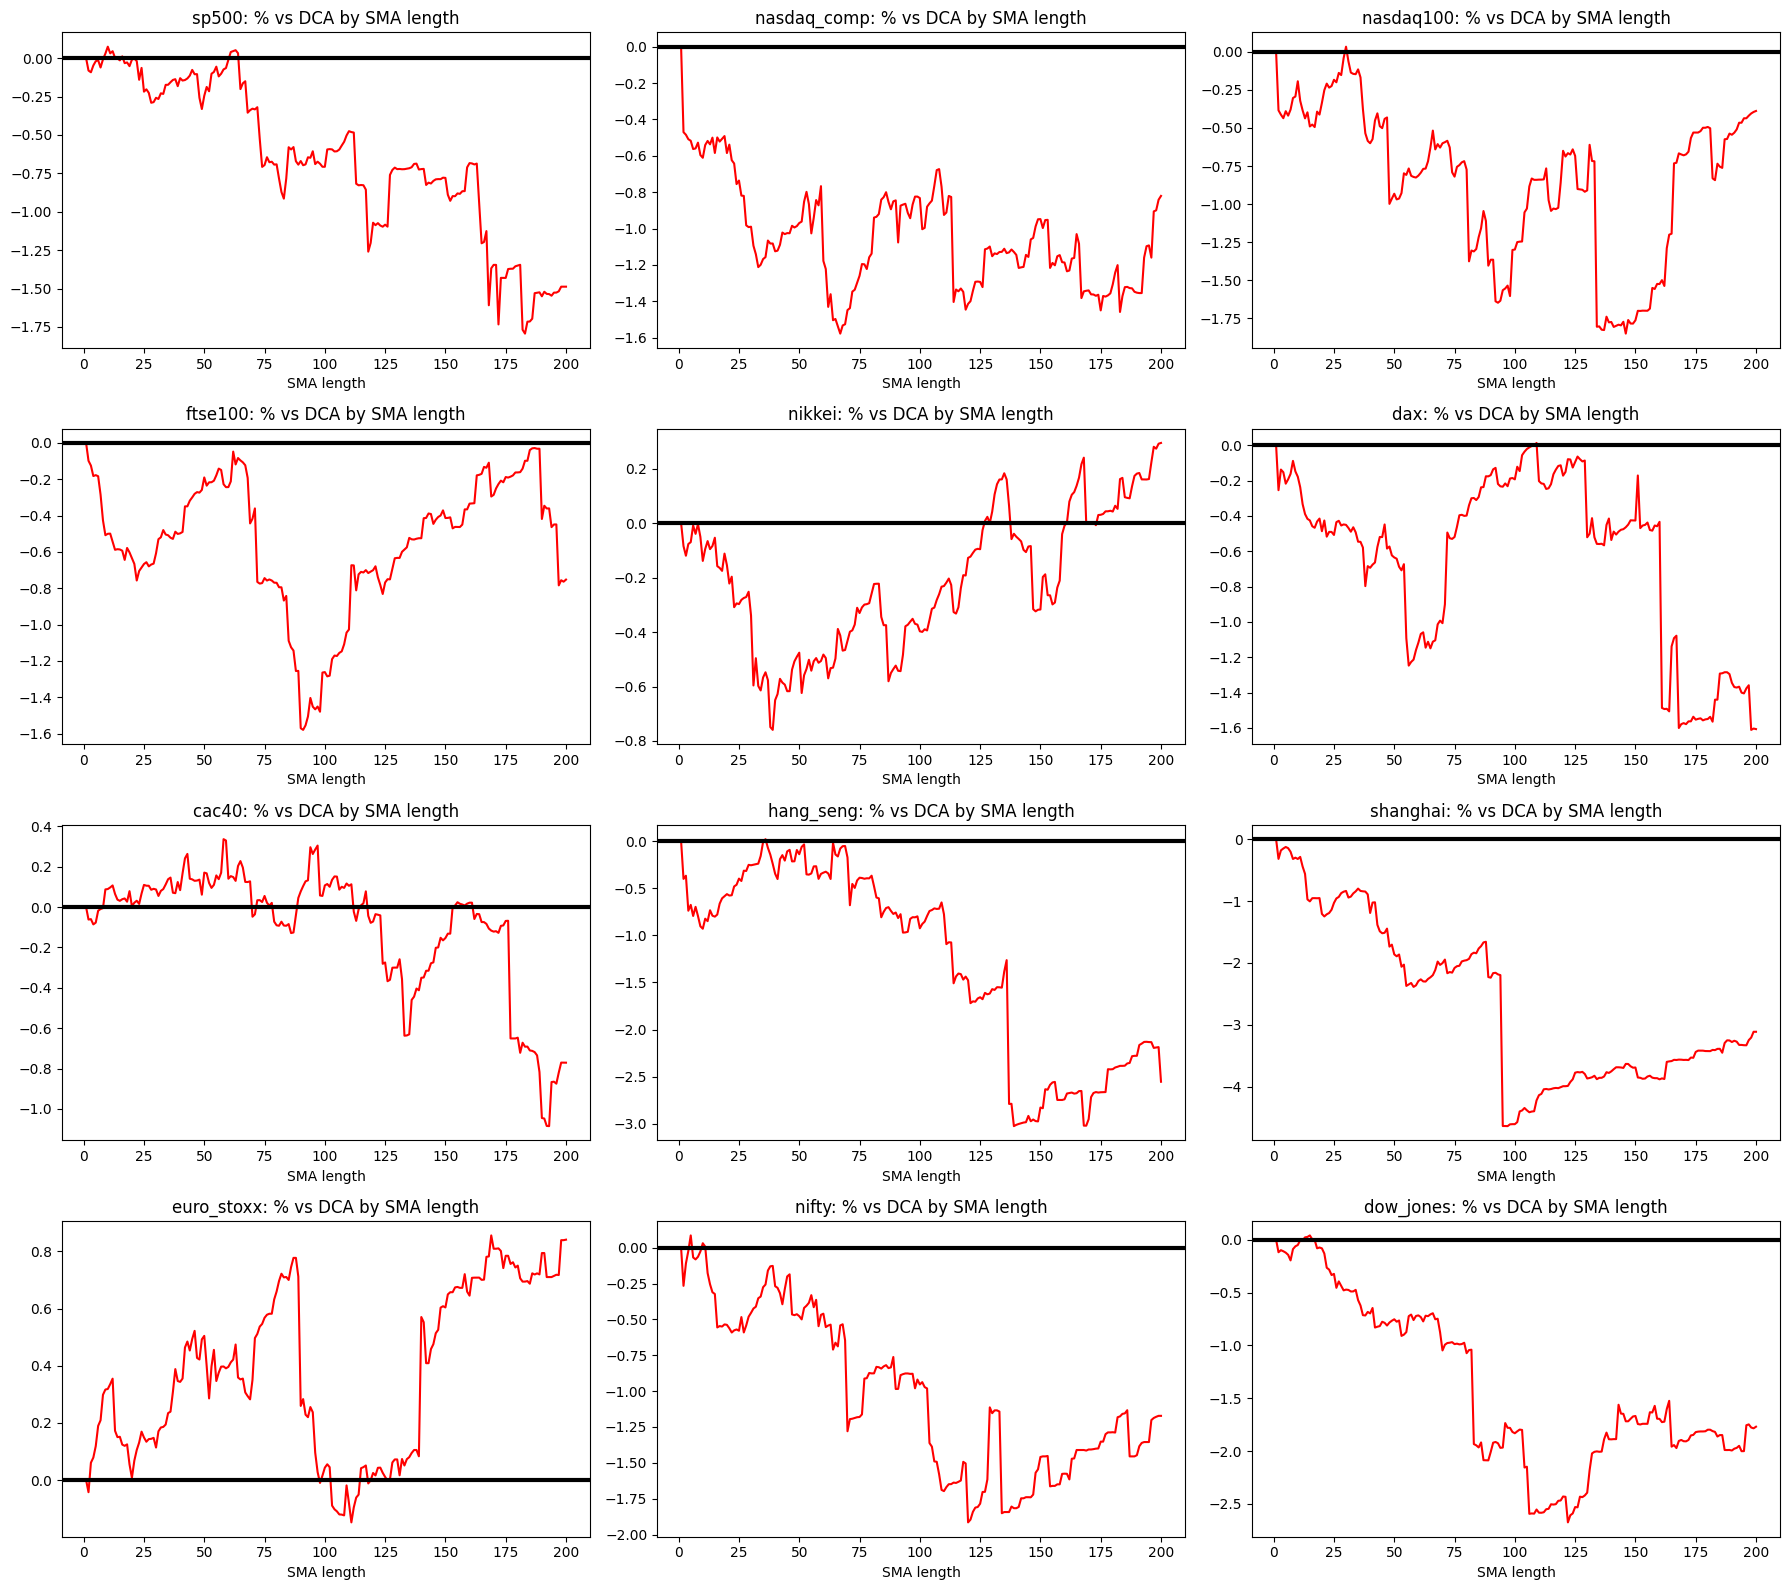

In [50]:
axes_4 = make_grid()
for i in range(len(names)):
    ax = axes_4[i]
    dca = finals[names[i]][0] # finals is organized by sma x not ranked yet its in order can use
    diffs = []
    for value in finals[names[i]]:
        diffs.append((value / dca - 1) * 100)  # calculates diff to dca in pp
    ax.plot(x_values, diffs, color="red")
    ax.axhline(0, color="black", linewidth=3)  # above this line = beats DCA
    ax.set_title(f"{names[i]}: % vs DCA by SMA length")
    ax.set_xlabel("SMA length")
plt.tight_layout()
plt.show()

sp500: 5%
nasdaq_comp: 0%
nasdaq100: 1%
ftse100: 0%
nikkei: 24%
dax: 1%
cac40: 52%
hang_seng: 1%
shanghai: 0%
euro_stoxx: 91%
nifty: 2%
dow_jones: 2%


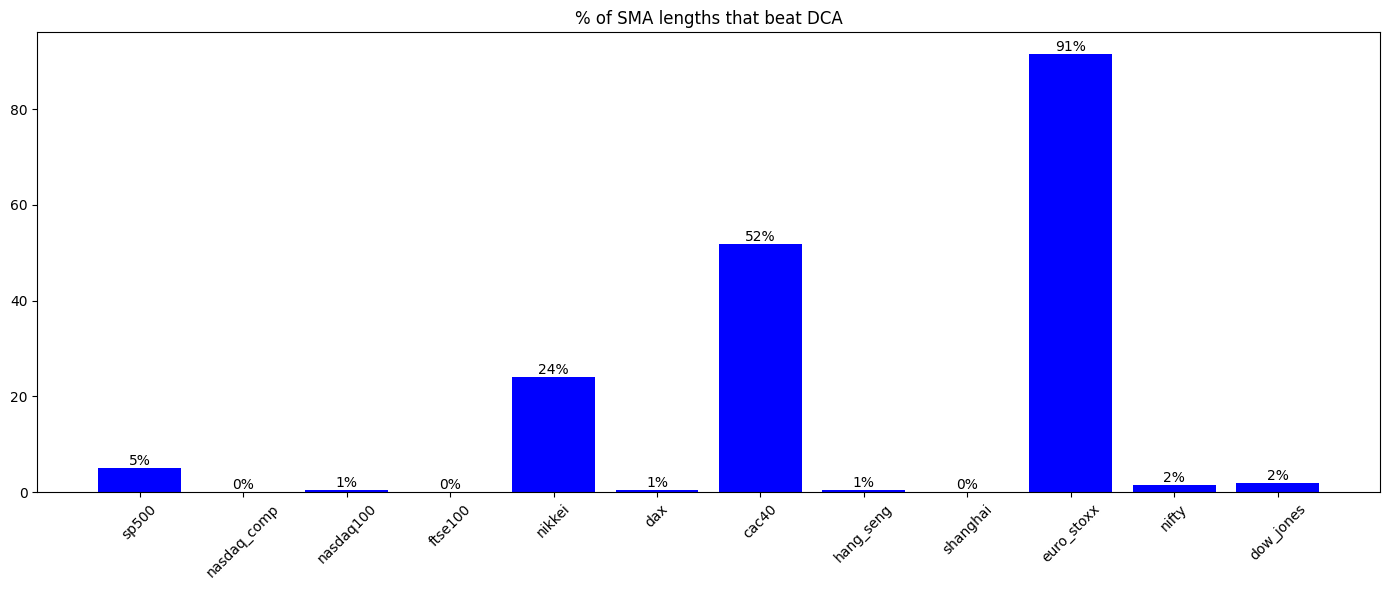

In [60]:
beat_pct = []
labels = []
for name in names: # for each of the indexes
    dca = finals[name][0] # the first value stored in each index = DCA
    beat = 0
    for value in finals[name]: 
        if value > dca:
            beat += 1
    pct_beat = beat / (len(finals[name]) - 1) * 100  # calculates % and -1 because len of final values - dca
    print(f"{name}: {pct_beat:.0f}%")
    beat_pct.append(pct_beat)
    labels.append(f"{pct_beat:.0f}%")

fig, ax = plt.subplots(1,1,figsize=(14, 6)) # fig = whole fig, ax= axes where data is actually plotted . figsize(wide,tall). plt.subplots(rows, cols) one plot is 1,1
bars = ax.bar(names, beat_pct, color="blue")
ax.bar_label(bars, labels=labels)
ax.set_title("% of SMA lengths that beat DCA")
ax.tick_params(axis="x", labelrotation=45)
plt.tight_layout()
plt.show()



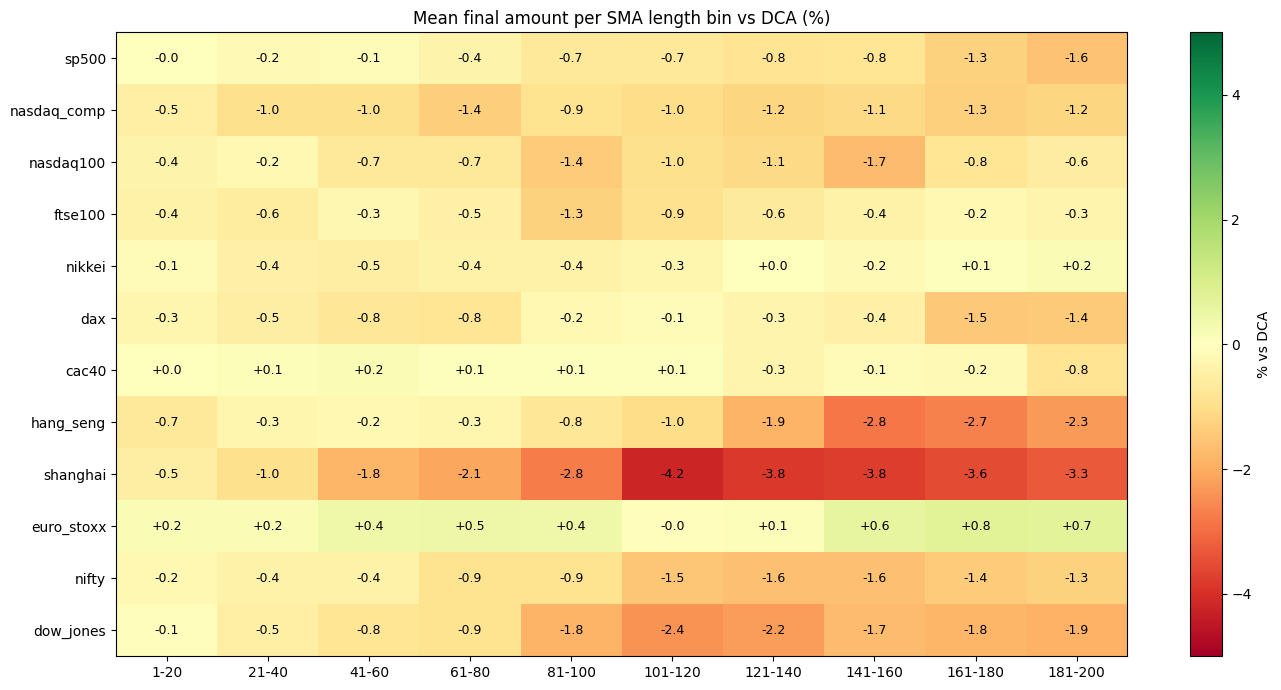

In [52]:
grid = []
for name in names:
    means = get_bin_means(finals[name])  # here is just one graph so can pass just the lists
    row = []
    for mean in means:
        row.append((mean / finals[name][0] - 1) * 100)  # mean / dca -1 * 100 gets the percentage difference 
    grid.append(row)   # row is list of percentage difference grid is list of lists

biggest = 5 # margin considered for visualization purposes, anything around or over this number will be dark red / green ( significant margin )
        # anything that loses/wins to dca by 5+% is considered very significant 

fig, ax = plt.subplots(figsize=(14, 7))
image = ax.imshow(grid, cmap="RdYlGn", vmin=-biggest, vmax=biggest,aspect="auto")  # imshow = grid, vmin/max = bottom of color scales, aspect auto makes wider/better
ax.set_xticks(range(10))
ax.set_xticklabels(bin_labels)
ax.set_yticks(range(12))
ax.set_yticklabels(names)
for r in range(12):
    for c in range(10):
        ax.text(c, r, f"{grid[r][c]:+.1f}", ha="center", va="center", fontsize=9) # column 1, row 1, "-0.0" check list of lists grid
fig.colorbar(image, label="% vs DCA")
ax.set_title("Mean final amount per SMA length bin vs DCA (%)")
plt.tight_layout()
plt.show()

In [53]:
hidden = 3   # points hidden on each side during cross-validation

def average(x_train, y_train, x_new, half): # x_train = SMA lengths available for training (excluding hidden points) array
# y_train = corresponding final values for those SMA lengths array # x_new = the SMA length being smoothed  i # half = window distance on each side of x_new  n

    mean_avg = y_train[np.abs(x_train - x_new) <= half].mean() # produces a mean of the final values of the valid sma i's considering the half 
    return mean_avg


def kernel(x_train, y_train, x_new, width): 

    # width is single number controlling how broadly nearby SMA lengths influence the estimate.
    kernel_mean = KernelReg(y_train, x_train, var_type="c", reg_type="lc", bw=[width]).fit([x_new])[0][0] 
#    var type tells is continuous numbers reg type uses local constant regression bw is bandwidth fit estimates new value at sma i 
# 0,0 extracts single predicted value bc that returns arrays so 0 selects prediction array second 0 extracts the only number in the array clean
    return kernel_mean


def loess(x_train, y_train, x_new, frac):  # frac is fraction of data points used for each local fit
    loess_mean = lowess(y_train, x_train, frac=frac, it=0, xvals=np.array([x_new]))[0]
        # x vals calculate estimate at this single SMA length, 
        # it is robustness iteration repeats the smoothing process giving less influence to points that don't fit well
    # 0 is because xvals contains one value, so lowess() returns one prediction in an array, and [0] extracts that number.
    return loess_mean


TESTS = {  # key: function to run, windows to try
    "average": (average, [4, 5, 8, 12, 20, 30]),           # half 
    "kernel": (kernel, [2, 3, 4, 6, 10, 15]),              # width
    "loess": (loess, [0.05, 0.1, 0.15, 0.2, 0.3, 0.5]),    # fracs
}

for name in names:
    if len(finals[name]) != len(x_values):
        print(f"{name} is missing SMAs")
        assert len(finals[name]) == len(x_values)

        

position_1_200 = np.array(x_values, dtype=float) # array of 1 to 200
positions = (np.array(x_values) - 1 ) # same as x but starting at 0 for the index iteration in the arrays

In [54]:
def cv_error(y, test, setting):
    total_error = 0
    for point in range(len(position_1_200)):
        keep = np.abs(positions - point) > hidden  # excludes neighbours 

        predicted = test(position_1_200[keep], y[keep], position_1_200[point], setting)  
        # x and y keep are the arrays with excluded sma i and its neighbours, x point is current sma
        error = predicted - y[point]
        total_error = total_error + error ** 2

    return total_error / len(y) # average squared error


best_settings = {}

for name in names: # for all 12 indexes
    y = np.array(finals[name]) # y is list of final values for each index
    best_settings[name] = {}

    for test_name, (test, settings) in TESTS.items():
        errors = [cv_error(y, test, setting) for setting in settings]  # runs all possible settings for each test
        best_settings[name][test_name] = settings[np.argmin(errors)] # saves in a dictionary the lowest error setting for each test , for each index
           

print(best_settings)

/home/pedrosalgado22/.local/lib/python3.14/site-packages/pandas/util/_decorators.py:220: FutureWarning: After 0.17 or January 2028, whichever comes first, the default behavior will switch to using an entropy initialized numpy.random.Generator.
  return func(*args, **kwargs)


{'sp500': {'average': 4, 'kernel': 2, 'loess': 0.05}, 'nasdaq_comp': {'average': 4, 'kernel': 2, 'loess': 0.05}, 'nasdaq100': {'average': 4, 'kernel': 2, 'loess': 0.05}, 'ftse100': {'average': 4, 'kernel': 2, 'loess': 0.05}, 'nikkei': {'average': 5, 'kernel': 2, 'loess': 0.05}, 'dax': {'average': 8, 'kernel': 3, 'loess': 0.05}, 'cac40': {'average': 4, 'kernel': 3, 'loess': 0.05}, 'hang_seng': {'average': 4, 'kernel': 2, 'loess': 0.05}, 'shanghai': {'average': 4, 'kernel': 2, 'loess': 0.05}, 'euro_stoxx': {'average': 4, 'kernel': 2, 'loess': 0.05}, 'nifty': {'average': 4, 'kernel': 2, 'loess': 0.05}, 'dow_jones': {'average': 4, 'kernel': 2, 'loess': 0.05}}


In [55]:
rows = []

for name in names: # for all 12 indexes
    y = np.array(finals[name]) # list of all final values
    row = {"index": name, "raw best": int(position_1_200[np.argmax(y)])} # converts the best x in sma x to int the highest original value

    for test_name, (test, _) in TESTS.items():
        setting = best_settings[name][test_name]  # grabs best setting from dict
        smoothed = [test(position_1_200, y, value, setting) for value in position_1_200]  # runs final smoothing test with cv setting

        row[test_name] = int(position_1_200[np.argmax(smoothed)])  # best sma x from the smoothed final values

    rows.append(row)

display(pd.DataFrame(rows))

,index,raw best,average,kernel,loess
0,sp500,10,12,11,11
1,nasdaq_comp,1,1,1,1
2,nasdaq100,30,31,30,30
3,ftse100,1,185,186,1
4,nikkei,200,200,200,200
5,dax,109,111,106,106
6,cac40,58,62,59,95
7,hang_seng,36,48,36,36
8,shanghai,1,2,1,1
9,euro_stoxx,169,172,200,200



ok from here on out its chat gpt time to shine coding told it to adapt my code to get time frame related information needed in order to perform white reality check and understand if there is some statistical significance to the best strategies i did not include time related info initially it was not my goal and since he can just adapt my earlier extractions plug info into arch reality check and then build table he should be alright i will check but cba doing a white reality test myself after this

In [56]:
from arch.bootstrap import RealityCheck

def simulate_reality_check(df, sma_timeframe, dividend_yield):
    dates = df.index.tolist()
    closes = df["Close"].tolist()

    if sma_timeframe is not None:
        smas = df[sma_timeframe].tolist()

    valid = df[(df.index >= START_DATE) & df["sma_200"].notna()]
    start = df.index.get_loc(valid.index[0])
    end = df.index.get_loc(valid.index[-1])

    cash = 0
    units = 0
    total_invested = 0
    next_payment = dates[start].replace(day=1) + pd.DateOffset(months=1)

    portfolio_values = []
    contributions = []

    for i in range(start, end + 1):
        days = (dates[i] - dates[i - 1]).days
        cash = cash * (1 + INTEREST_RATE) ** (days / 365)
        units = units * (1 + dividend_yield) ** (days / 365)

        contribution_today = 0

        while next_payment <= dates[i]:
            cash += PAYMENT
            contribution_today += PAYMENT
            total_invested += PAYMENT
            next_payment += pd.DateOffset(months=1)

        if sma_timeframe is None:
            signal = True
        else:
            signal = closes[i - 1] < smas[i - 1]

        if cash > 0 and signal == True:
            units += cash / closes[i - 1]
            cash = 0

        portfolio_values.append(units * closes[i] + cash)
        contributions.append(contribution_today)

    values = np.array(portfolio_values, dtype=float)
    contributions = np.array(contributions, dtype=float)

    # Calculate returns without treating new deposits as investment gains
    previous_values = np.r_[np.nan, values[:-1]]
    invested_value = previous_values + contributions

    daily_returns = np.full(len(values), np.nan)
    valid_returns = invested_value > 0
    daily_returns[valid_returns] = (
        values[valid_returns] / invested_value[valid_returns] - 1
    )

    strategy_name = sma_timeframe if sma_timeframe is not None else "DCA"

    return pd.Series(
        daily_returns,
        index=df.index[start:end + 1],
        name=strategy_name
    )


def run_index_simulator_reality_check(df, name):
    returns = []

    for strategy, sma_timeframe in STRATEGIES.items():
        returns.append(
            simulate_reality_check(
                df, sma_timeframe, DIV_YIELD[name]
            )
        )

    return pd.concat(returns, axis=1)

In [57]:
returns_by_index = {}

for name in DIV_YIELD:
    df = pd.read_csv(
        processed_data_path / f"{name}_processed.csv",
        index_col=0,
        parse_dates=True
    )

    returns_by_index[name] = run_index_simulator_reality_check(df, name)

In [58]:
ALPHA = 0.05
REPS = 1000

def wrc_pvalue(benchmark, models):
    data = pd.concat(
        [benchmark.rename("DCA"), models],
        axis=1
    )

    data = data.replace([np.inf, -np.inf], np.nan).dropna()

    test = RealityCheck(
        benchmark=-data["DCA"],
        models=-data[models.columns],
        reps=REPS,
        bootstrap="stationary",
        seed=123
    )

    test.compute()

    # Upper p-value: conservative White Reality Check result
    return float(test.pvalues["upper"])

In [59]:
rows = []

for name, returns in returns_by_index.items():
    summary = all_tables[all_tables["index"] == name].copy()

    # Keep SMA strategies, excluding DCA
    sma_summary = summary[
        summary["strategy_simulated"].astype(str).str.fullmatch(r"sma_\d+")
    ].copy()

    sma_summary["sma"] = (
        sma_summary["strategy_simulated"]
        .str.extract(r"sma_(\d+)")
        .astype(int)
    )

    sma_cols = sorted(
        [c for c in returns.columns
         if str(c).startswith("sma_") and str(c).split("_")[-1].isdigit()],
        key=lambda c: int(c.split("_")[-1])
    )

    # Best individual SMA according to final value
    best_row = sma_summary.loc[sma_summary["final_value"].idxmax()]

    row = {
        "index": name,
        "best SMA": int(best_row["sma"]),
        "best SMA final value": best_row["final_value"],
        "WRC p (all SMAs)": wrc_pvalue(
            returns["DCA"], returns[sma_cols]
        )
    }

    row["SMA significant"] = row["WRC p (all SMAs)"] < ALPHA

    for width in [5, 10, 20]:
        # Find the bin with the highest mean final value
        sma_summary["bin_start"] = (
            (sma_summary["sma"] - 1) // width
        ) * width + 1

        bin_means = sma_summary.groupby("bin_start")["final_value"].mean()
        best_start = int(bin_means.idxmax())

        row[f"best bin ({width})"] = (
            f"{best_start}-{best_start + width - 1}"
        )
        row[f"mean final value ({width})"] = bin_means.loc[best_start]

        # Average the daily returns of the SMA strategies within each bin
        groups = {}

        for col in sma_cols:
            sma = int(col.split("_")[-1])
            bin_start = ((sma - 1) // width) * width + 1
            bin_name = f"{bin_start}-{bin_start + width - 1}"
            groups.setdefault(bin_name, []).append(col)

        bin_returns = pd.DataFrame({
            bin_name: returns[cols].mean(axis=1)
            for bin_name, cols in groups.items()
        })

        p = wrc_pvalue(returns["DCA"], bin_returns)

        row[f"WRC p (bins {width})"] = p
        row[f"bins {width} significant"] = p < ALPHA

    rows.append(row)

wrc_results = pd.DataFrame(rows)
display(wrc_results)

,index,best SMA,best SMA final value,WRC p (all SMAs),SMA significant,best bin (5),mean final value (5),WRC p (bins 5),bins 5 significant,best bin (10),mean final value (10),WRC p (bins 10),bins 10 significant,best bin (20),mean final value (20),WRC p (bins 20),bins 20 significant
0,sp500,10,"4,116,748.50",0.92,False,11-15,"4,114,193.20",0.84,False,11-20,"4,113,480.11",0.83,False,1-20,"4,113,100.27",0.85,False
1,nasdaq_comp,2,"6,552,527.50",0.93,False,1-5,"6,550,880.50",0.93,False,11-20,"6,548,689.32",0.92,False,1-20,"6,548,407.26",0.92,False
2,nasdaq100,30,"12,669,500.25",0.70,False,26-30,"12,652,594.95",0.68,False,21-30,"12,644,944.97",0.69,False,21-40,"12,636,928.89",0.73,False
3,ftse100,187,"1,852,817.21",0.94,False,181-185,"1,851,343.83",0.89,False,181-190,"1,851,340.11",0.91,False,161-180,"1,849,523.50",0.89,False
4,nikkei,200,"1,166,537.88",0.92,False,196-200,"1,166,283.25",0.91,False,191-200,"1,165,660.00",0.91,False,181-200,"1,165,092.24",0.91,False
5,dax,109,"1,330,908.39",0.74,False,106-110,"1,330,177.63",0.72,False,101-110,"1,329,947.52",0.71,False,101-120,"1,329,109.71",0.73,False
6,cac40,58,"906,486.34",0.62,False,56-60,"905,462.10",0.59,False,51-60,"905,040.53",0.59,False,41-60,"904,957.22",0.59,False
7,hang_seng,36,"1,277,796.87",0.93,False,66-70,"1,276,203.60",0.93,False,31-40,"1,275,384.81",0.93,False,41-60,"1,274,609.98",0.91,False
8,shanghai,5,"399,222.46",0.81,False,1-5,"398,950.84",0.87,False,1-10,"398,809.92",0.84,False,1-20,"397,548.53",0.80,False
9,euro_stoxx,169,"285,669.56",0.34,False,196-200,"285,485.97",0.43,False,171-180,"285,438.88",0.49,False,161-180,"285,398.95",0.50,False
